
## Predicting Annual Medical Insurance Premiums — Business Problem

Business problem: A health insurance provider wants to develop a transparent and interpretable machine learning model to estimate the annual medical insurance premium for each customer based on their demographic, lifestyle and health-related characteristics. The model should help the provider understand how different factors, such as age, BMI, smoking status and chronic conditions, are associated with premium amounts, while supporting consistent, data-driven premium estimation.

Target variable (Y):\- `annual_premium` — the annual medical insurance premium in USD. It is a continuous numerical variable.

Independent variables (X):

- Demographic: `age`, `sex`, `region`
- Lifestyle: `smoker`, `exercise_freq`
- Health-related: `bmi`, `chronic_conditions`, `blood_pressure`, `cholesterol`
- Financial/family-related: `annual_income`, `children`

**Technique-Linear Regression**

**Business objective:** Build a model that predicts premiums with reasonable accuracy while maintaining interpretability and evaluating whether its assumptions are appropriate for the data.

**Expected outcome:** An interpretable prediction model that identifies relevant premium-associated factors and supports further analysis by insurance stakeholders.

## 0. Environment setup

In [1]:
#Core numerical/data handling
import numpy as np
import pandas as pd

#Plotting
import matplotlib.pyplot as plt
import seaborn as sns

#Statistics/hypothesis testing
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

#scikit-learn:imputation,preprocessing,modelling,metrics
from sklearn.experimental import enable_iterative_imputer #noqa:F401 (needed to expose IterativeImputer)
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

# Cosmetic settings
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data import and first look

In [2]:
# Load the raw dataset
df=pd.read_csv("/content/insurance_premium.csv")

# Shape: how many rows (members) and columns (features + target)?
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")

#First five cols
df.head()

The dataset has 2500 rows and 12 columns.


,age,sex,bmi,children,smoker,region,exercise_freq,chronic_conditions,annual_income,blood_pressure,cholesterol,annual_premium
0,22,female,26.2,0,no,southwest,occasional,1,94107.0,129.0,156.0,18468.50
1,54,male,25.8,0,no,northeast,regular,0,65748.0,141.0,217.0,24997.08
2,48,female,33.1,1,no,northeast,occasional,0,76640.0,138.0,184.0,32115.51
3,38,male,33.4,0,no,southeast,occasional,0,85783.0,132.0,214.0,25185.38
4,38,male,NaN,0,no,southwest,regular,2,32857.0,138.0,208.0,24202.80


In [3]:
# A random sample often reveals data quirks that head()/tail() hide
df.sample(5,random_state=RANDOM_STATE)

,age,sex,bmi,children,smoker,region,exercise_freq,chronic_conditions,annual_income,blood_pressure,cholesterol,annual_premium
1447,63,male,22.2,0,no,northwest,regular,0,73816.0,142.0,182.0,26265.78
1114,27,female,NaN,1,no,northeast,none,1,84833.0,123.0,144.0,24345.70
1064,53,female,NaN,1,no,northwest,regular,2,91658.0,113.0,204.0,33828.87
2287,56,male,15.1,1,yes,northeast,regular,1,59624.0,142.0,187.0,43778.14
1537,23,female,20.3,2,no,northeast,regular,1,87856.0,133.0,221.0,22937.08


In [4]:
# Column names and a one-line data dictionary for the audience
data_dictionary={
    "age":          "Members age in years",
    "sex":          "Biological sex (male/female)",
    "bmi":          "Body mass index (kg/m^2)",
    "children":     "Number of dependents covered by policy",
    "smoker":       "Smoker status (yes/no)",
    "region":             "Residential region",
    "exercise_freq":      "Weekly exercise habit (none/occasional/regular)",
    "chronic_conditions": "Count of diagnosed chronic illnesses",
    "annual_income":      "Member's annual income (USD)",
    "blood_pressure":     "Systolic blood pressure (mmHg)",
    "cholesterol":        "Total cholesterol (mg/dL)",
    "annual_premium":     "TARGET - annual insurance premium billed (USD)",

}
pd.DataFrame(list(data_dictionary.items()),columns=['features','description'])

,features,description
0,age,Members age in years
1,sex,Biological sex (male/female)
2,bmi,Body mass index (kg/m^2)
3,children,Number of dependents covered by policy
4,smoker,Smoker status (yes/no)
5,region,Residential region
6,exercise_freq,Weekly exercise habit (none/occasional/regular)
7,chronic_conditions,Count of diagnosed chronic illnesses
8,annual_income,Member's annual income (USD)
9,blood_pressure,Systolic blood pressure (mmHg)


## 2. Data statistics BEFORE cleaning

In [5]:
# Data types, non-null counts and memory footprint
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 2500 non-null   int64  
 1   sex                 2500 non-null   object 
 2   bmi                 2350 non-null   float64
 3   children            2500 non-null   int64  
 4   smoker              2450 non-null   object 
 5   region              2500 non-null   object 
 6   exercise_freq       2425 non-null   object 
 7   chronic_conditions  2500 non-null   int64  
 8   annual_income       2375 non-null   float64
 9   blood_pressure      2400 non-null   float64
 10  cholesterol         2400 non-null   float64
 11  annual_premium      2500 non-null   float64
dtypes: float64(5), int64(3), object(4)
memory usage: 234.5+ KB


In [6]:
# Statistical summary of NUMERIC columns (count, mean, std, min, quartiles, max)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2500.0,40.917200,13.554093,18.00,29.00,41.00,53.0000,64.000000
bmi,2350.0,28.652305,6.411850,15.00,24.40,28.50,32.5000,87.681964
children,2500.0,1.128400,1.263864,0.00,0.00,1.00,2.0000,5.000000
chronic_conditions,2500.0,0.682400,0.881499,0.00,0.00,0.00,1.0000,3.000000
annual_income,2375.0,63840.936748,29901.313234,15000.00,47372.00,63341.00,77920.0000,549561.210011
blood_pressure,2400.0,122.398333,14.841545,90.00,112.00,122.00,132.0000,175.000000
cholesterol,2400.0,196.476667,34.016514,120.00,173.00,197.00,219.0000,311.000000
annual_premium,2500.0,28840.743264,7841.318669,11997.23,23412.47,27530.04,33056.5425,90112.290000


In [7]:
# Statistical summary of CATEGORICAL / object columns
df.describe(include='object').T

,count,unique,top,freq
sex,2500,2,male,1268
smoker,2450,2,no,1973
region,2500,4,southeast,716
exercise_freq,2425,3,occasional,963


In [8]:
# Missing-value audit: count and percentage per column
missing =pd.DataFrame({
    "missing_count":df.isna().sum(),
    "missing_pct":(df.isna().mean()*100).round(2)
}).sort_values("missing_count",ascending=False)
missing[missing['missing_count']>0]

,missing_count,missing_pct
bmi,150,6.0
annual_income,125,5.0
blood_pressure,100,4.0
cholesterol,100,4.0
exercise_freq,75,3.0
smoker,50,2.0


In [9]:
target='annual_premium'
numeric_cols=df.select_dtypes(include='number').columns.drop(target).tolist()
categorical_cols=df.select_dtypes(include='object').columns.tolist()
print("Numerical Columns:",numeric_cols)
print("Categorical Columns:",categorical_cols)
print("Target:",target)

Numerical Columns: ['age', 'bmi', 'children', 'chronic_conditions', 'annual_income', 'blood_pressure', 'cholesterol']
Categorical Columns: ['sex', 'smoker', 'region', 'exercise_freq']
Target: annual_premium


## 3. Exploratory Data Analysis (EDA) plots

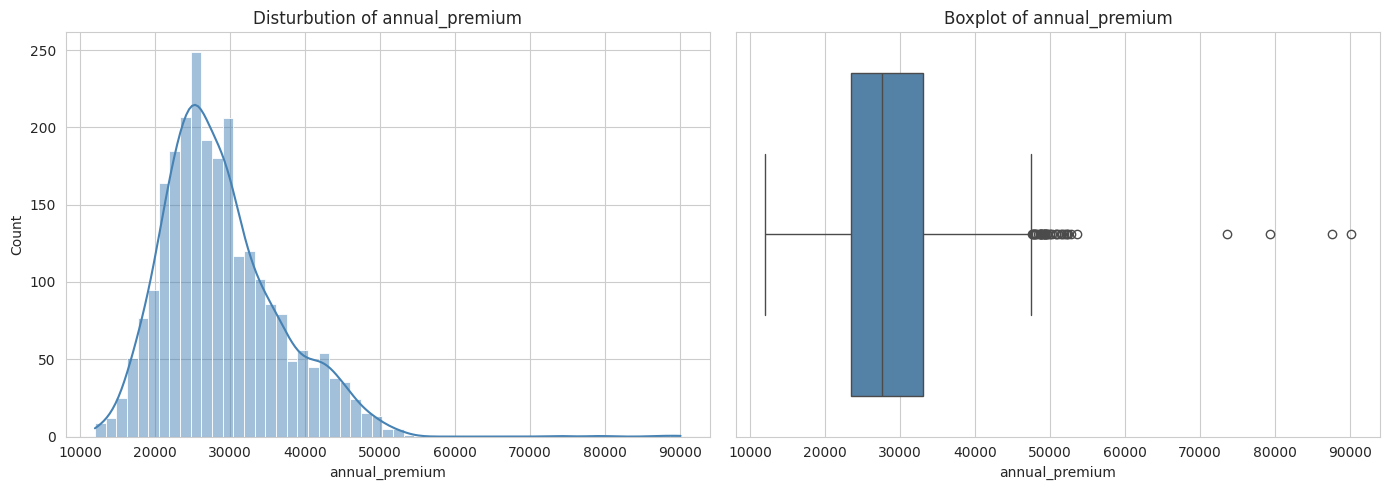

Skewness of target:1.110


In [10]:
# 3a. Distribution of the target variable
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.histplot(df[target],kde=True,ax=ax[0],color='steelblue')
ax[0].set_title("Disturbution of annual_premium")
sns.boxplot(x=df[target],ax=ax[1],color='steelblue')
ax[1].set_title("Boxplot of annual_premium")
plt.tight_layout();
plt.show()

print(f"Skewness of target:{df[target].skew():.3f}")

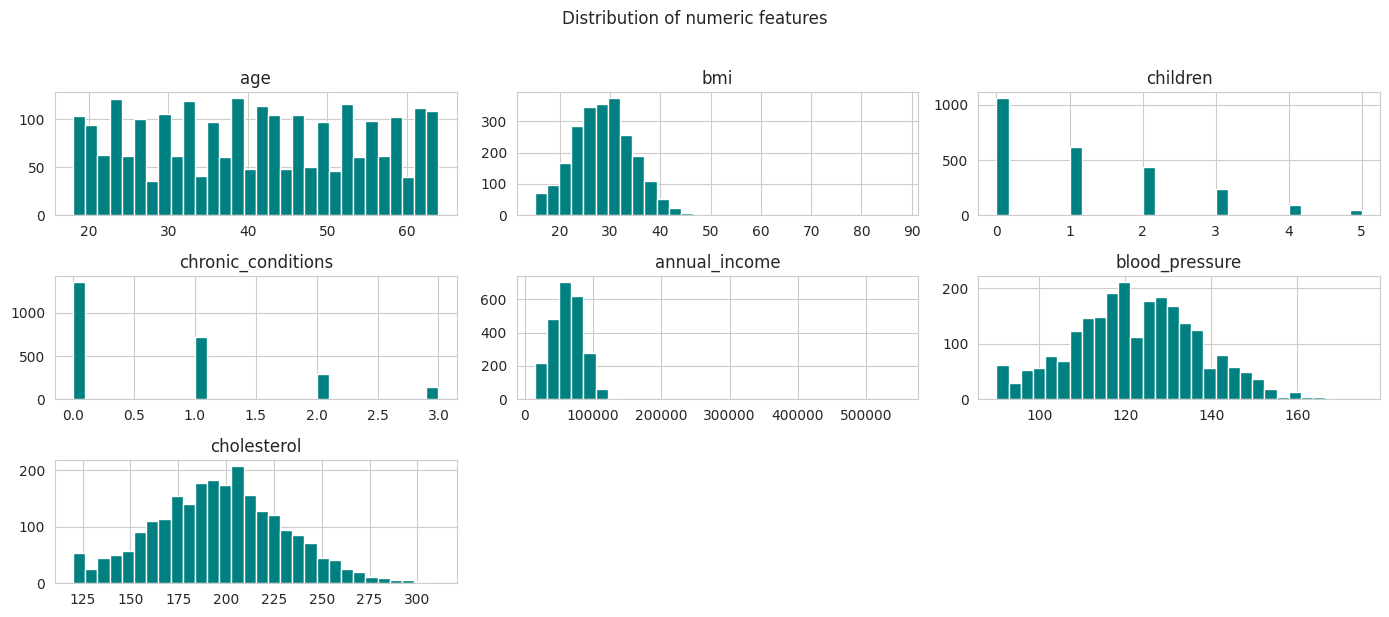

In [11]:
# 3b. Histograms of all numeric features
df[numeric_cols].hist(bins=30,figsize=(14,6),color='teal',edgecolor='white')
plt.suptitle("Distribution of numeric features",y=1.02)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3668/3332681504.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col,data=df,ax=ax,palette='viridis')
/tmp/ipykernel_3668/3332681504.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col,data=df,ax=ax,palette='viridis')
/tmp/ipykernel_3668/3332681504.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col,data=df,ax=ax,palette='viridis')
/tmp/ipykernel_3668/3332681504.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

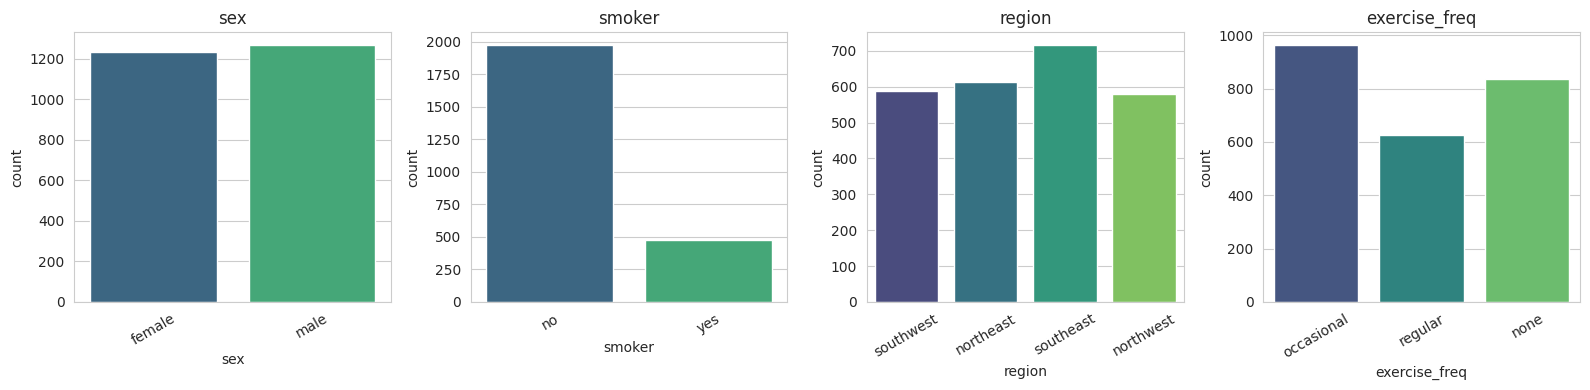

In [12]:
# 3c. Count plots for categorical features
fig,axes=plt.subplots(1,len(categorical_cols),figsize=(16,4))
for ax,col in zip(axes,categorical_cols):
  sns.countplot(x=col,data=df,ax=ax,palette='viridis')
  ax.set_title(col)
  ax.tick_params(axis='x',rotation=30)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3668/3750881083.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="smoker",y=target,data=df,ax=axes[0],palette='Set2')
/tmp/ipykernel_3668/3750881083.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='exercise_freq',y=target,data=df,ax=axes[1],palette='Set2')
/tmp/ipykernel_3668/3750881083.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='region',y=target,data=df,ax=axes[2],palette='Set2')


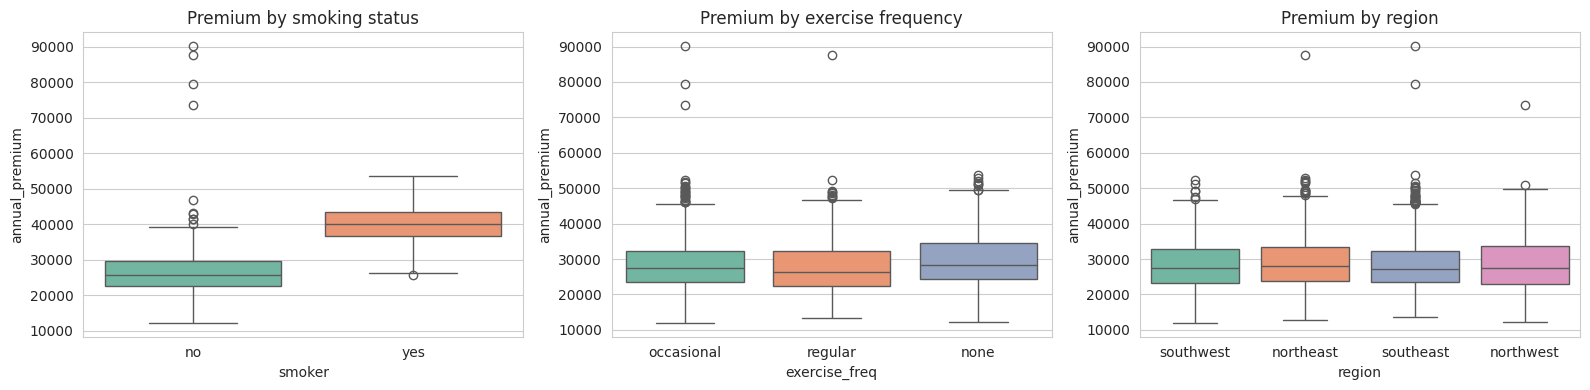

In [13]:
# 3d. How does the premium differ across key categories?
fig,axes=plt.subplots(1,3,figsize=(16,4))
sns.boxplot(x="smoker",y=target,data=df,ax=axes[0],palette='Set2')
axes[0].set_title("Premium by smoking status")
sns.boxplot(x='exercise_freq',y=target,data=df,ax=axes[1],palette='Set2')
axes[1].set_title("Premium by exercise frequency")
sns.boxplot(x='region',y=target,data=df,ax=axes[2],palette='Set2')
axes[2].set_title("Premium by region")
plt.tight_layout()
plt.show()

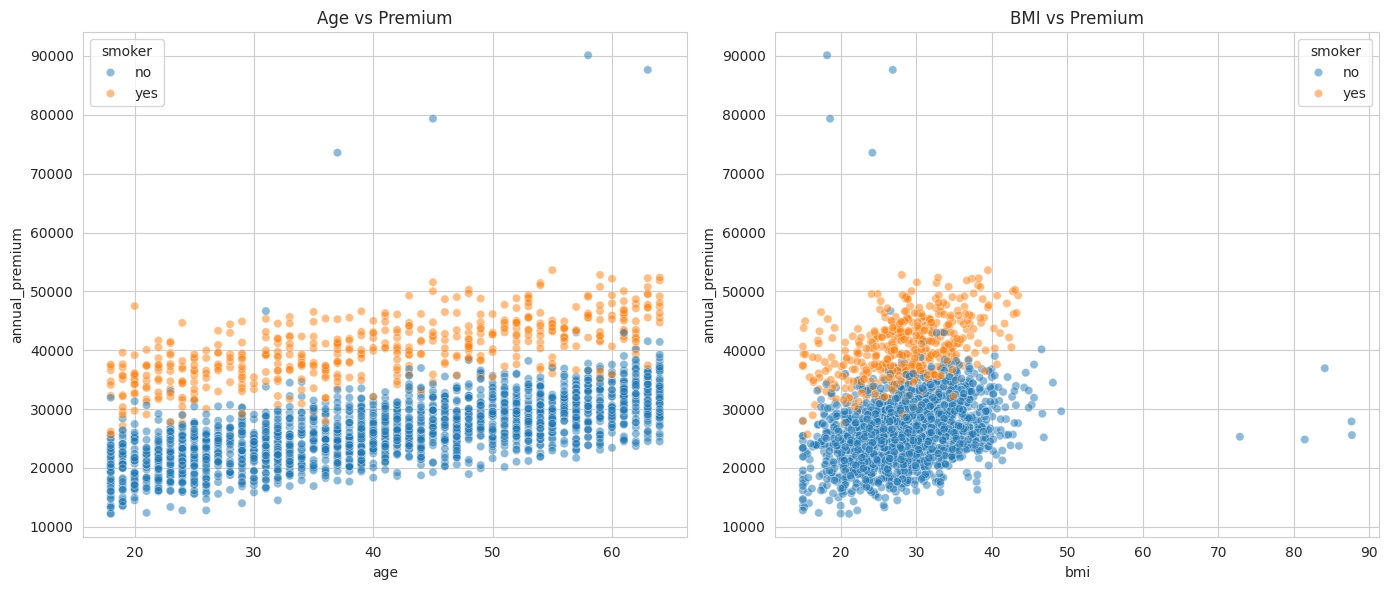

In [14]:
# 3e. Scatter of the two strongest expected numeric drivers vs premium, coloured by smoker
fig,axes=plt.subplots(1,2,figsize=(14,6))
sns.scatterplot(x='age',y=target,hue='smoker',data=df,ax=axes[0],alpha=0.5)
axes[0].set_title("Age vs Premium")
sns.scatterplot(x='bmi',y=target,hue='smoker',data=df,ax=axes[1],alpha=0.5)
axes[1].set_title("BMI vs Premium")
plt.tight_layout()
plt.show()

## 4. Correlations BEFORE cleaning

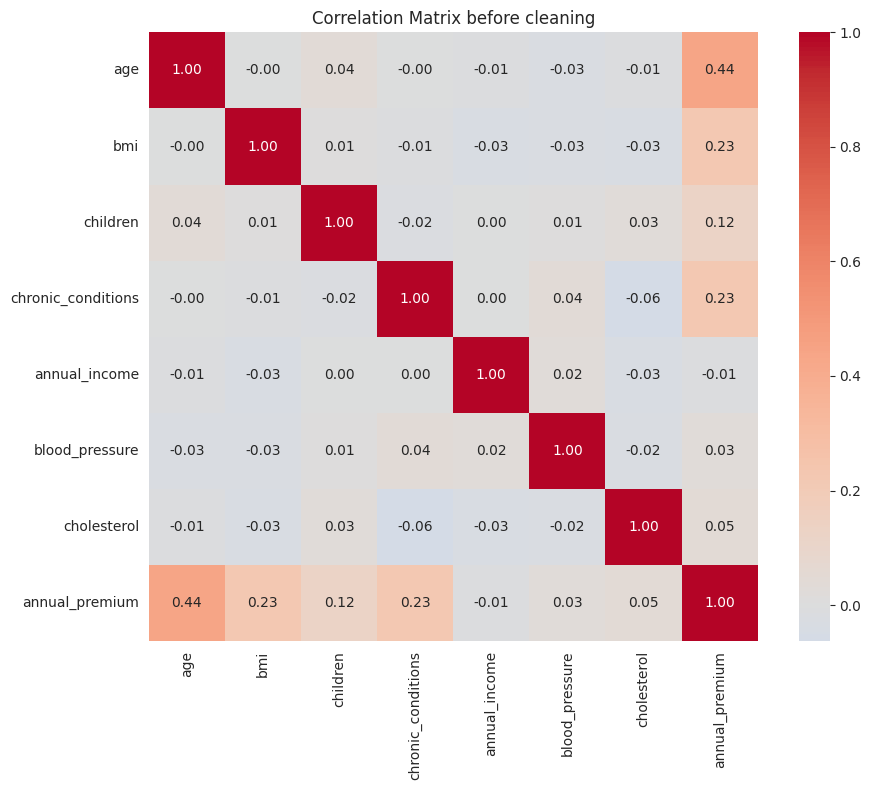

In [15]:
# Correlation matrix on raw numeric data (pandas ignores NaNs pairwise)
corr_before=df[numeric_cols+[target]].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_before,annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True)
plt.title("Correlation Matrix before cleaning")
plt.tight_layout()
plt.show()

In [16]:
# Correlation of each feature WITH the target, ranked
corr_before[target].drop(target).sort_values(key=abs,ascending=False)

,annual_premium
age,0.442986
bmi,0.226829
chronic_conditions,0.225073
children,0.120797
cholesterol,0.047260
blood_pressure,0.028961
annual_income,-0.009647


## 5. Outlier detection - IQR method and box plots

In [17]:
# 5a. Function that returns the IQR bounds and outlier count for a column
def iqr_bounds(series,k=1.5):
  q1,q3=series.quantile(0.25),series.quantile(0.75)
  iqr=q3-q1
  lower,upper=q1-k*iqr,q3+k*iqr
  outlier_count=(series<lower).sum()+(series>upper).sum()
  return lower,upper

outlier_report=[]
for col in numeric_cols+[target]:
  lower,upper=iqr_bounds(df[col])
  n_out=((df[col]<lower)|(df[col]>upper)).sum()
  outlier_report.append([col,round(lower,1),round(upper,1),int(n_out)])

pd.DataFrame(outlier_report,columns=['feature','lower_bound','upper_bound','n_outliers'])


,feature,lower_bound,upper_bound,n_outliers
0,age,-7.0,89.0,0
1,bmi,12.2,44.7,16
2,children,-3.0,5.0,0
3,chronic_conditions,-1.5,2.5,137
4,annual_income,1550.0,123742.0,10
5,blood_pressure,82.0,162.0,8
6,cholesterol,104.0,288.0,13
7,annual_premium,8946.4,47522.7,42


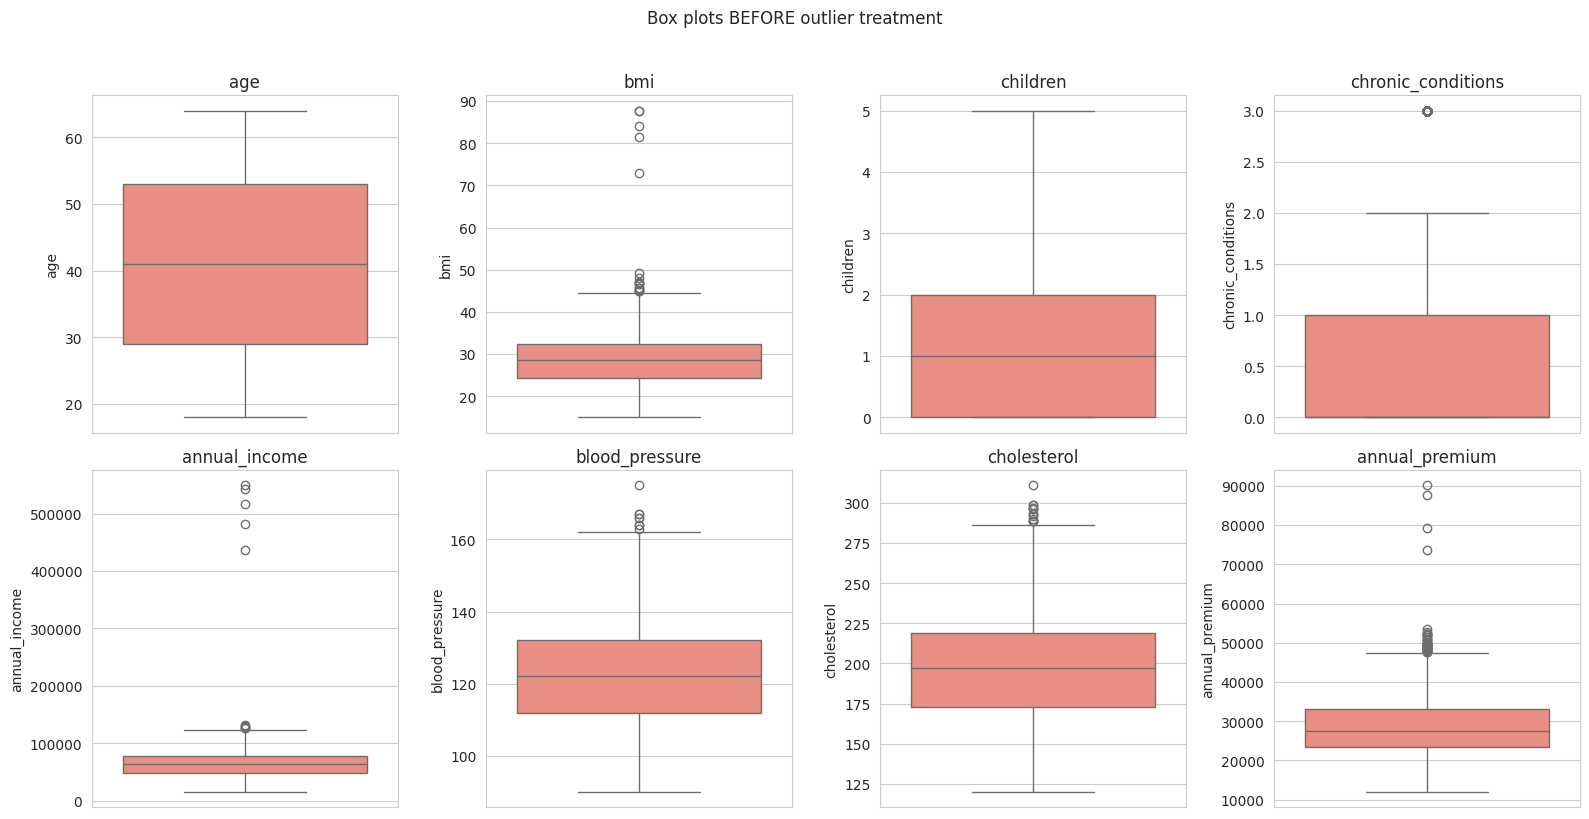

In [18]:
# 5b. Box plots make the outliers visible at a glance
cols_to_plot=numeric_cols+[target]
fig,axes=plt.subplots(2,4,figsize=(16,8))
for ax,col in zip(axes.ravel(),cols_to_plot):
  sns.boxplot(y=df[col], ax=ax,color='salmon')
  ax.set_title(col)

#hide any unused subplot
for ax in axes.ravel()[len(cols_to_plot):]:
  ax.axis("off")

plt.suptitle("Box plots BEFORE outlier treatment", y=1.02)
plt.tight_layout()
plt.show()

In [19]:
# 5c. Cap (winsorise) numeric features and the target at their IQR bounds.
# We work on a copy so the raw df stays available for comparison.
df_capped=df.copy()
for col in numeric_cols+[target]:
  lower,upper=iqr_bounds(df[col])
  df_capped[col]=df_capped[col].clip(lower=lower,upper=upper)

#Confirm outliers are gone
after=[]
for col in numeric_cols+[target]:
  lower,upper=iqr_bounds(df_capped[col])
  after.append([col,int(((df_capped[col]<lower)|(df_capped[col]>upper)).sum())])
print("Remaining IQR-flagged points after capping (small residual counts are normal):")
pd.DataFrame(after,columns=['features','n_outliers_after'])

Remaining IQR-flagged points after capping (small residual counts are normal):


,features,n_outliers_after
0,age,0
1,bmi,0
2,children,0
3,chronic_conditions,0
4,annual_income,0
5,blood_pressure,0
6,cholesterol,0
7,annual_premium,0


## 6. Missing-value imputation

In [20]:
# 6a. Demonstrate that mean / median / mode give DIFFERENT fills on one column (bmi)
demo_mean=df_capped['bmi'].fillna(df_capped['bmi'].mean())
demo_median=df_capped['bmi'].fillna(df_capped['bmi'].median())
demo_mode=df_capped['bmi'].fillna(df_capped['bmi'].mode()[0])
print(f"bmi mean fill   : {df_capped['bmi'].mean():.2f}")
print(f"bmi median fill : {df_capped['bmi'].median():.2f}")
print(f"bmi mode fill   : {df_capped['bmi'].mode()[0]:.2f}")


bmi mean fill   : 28.56
bmi median fill : 28.50
bmi mode fill   : 28.20


In [21]:
# 6b.categorical columns: mode imputation
df_clean=df_capped.copy()
mode_imputer=SimpleImputer(strategy='most_frequent')
df_clean[categorical_cols]=mode_imputer.fit_transform(df_clean[categorical_cols])
print("Categorical missing values after mode imputation:")
print(df_clean[categorical_cols].isna().sum())

Categorical missing values after mode imputation:
sex              0
smoker           0
region           0
exercise_freq    0
dtype: int64


In [22]:
# 6c. numeric columns: KNN imputation (k=5)
# KNN uses the other numeric features to estimate each missing value.
knn_imputer=KNNImputer(n_neighbors=5,weights='distance')
df_clean[numeric_cols]=knn_imputer.fit_transform(df_clean[numeric_cols])
print("Numeric missing values after KNN imputation:")
print(df_clean[numeric_cols].isna().sum())

Numeric missing values after KNN imputation:
age                   0
bmi                   0
children              0
chronic_conditions    0
annual_income         0
blood_pressure        0
cholesterol           0
dtype: int64


In [23]:
# 6d. Confirm the dataset is now completely clean (zero missing anywhere)
assert df_clean.isna().sum().sum()==0,"There are still missing values!"
print("No missing values remain.Cleaning complete")

No missing values remain.Cleaning complete


## 7. Data statistics AFTER cleaning

In [24]:
# Post-cleaning numeric summary
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2500.0,40.917200,13.554093,18.00,29.00,41.00,53.00000,64.00000
bmi,2500.0,28.537960,5.770620,15.00,24.60,28.40,32.20000,44.65000
children,2500.0,1.128400,1.263864,0.00,0.00,1.00,2.00000,5.00000
chronic_conditions,2500.0,0.655000,0.814211,0.00,0.00,0.00,1.00000,2.50000
annual_income,2500.0,63042.596839,21546.462682,15000.00,48288.25,63349.00,77226.25935,123742.00000
blood_pressure,2500.0,122.348706,14.552342,90.00,113.00,122.00,132.00000,162.00000
cholesterol,2500.0,196.588854,33.301180,120.00,175.00,197.00,218.00000,288.00000
annual_premium,2500.0,28750.765489,7480.448364,11997.23,23412.47,27530.04,33056.54250,47522.65125


In [25]:
# Side-by-side comparison of mean and std, before vs after cleaning
compare=pd.DataFrame({
    'mean_before': df[numeric_cols+[target]].mean(),
    'mean_after': df_clean[numeric_cols+[target]].mean(),
    'std_before': df[numeric_cols+[target]].std(),
    'std_after': df_clean[numeric_cols+[target]].std()
}).round(2)
compare

,mean_before,mean_after,std_before,std_after
age,40.92,40.92,13.55,13.55
bmi,28.65,28.54,6.41,5.77
children,1.13,1.13,1.26,1.26
chronic_conditions,0.68,0.66,0.88,0.81
annual_income,63840.94,63042.60,29901.31,21546.46
blood_pressure,122.40,122.35,14.84,14.55
cholesterol,196.48,196.59,34.02,33.30
annual_premium,28840.74,28750.77,7841.32,7480.45


## 8. Correlations and scatter plots AFTER cleaning

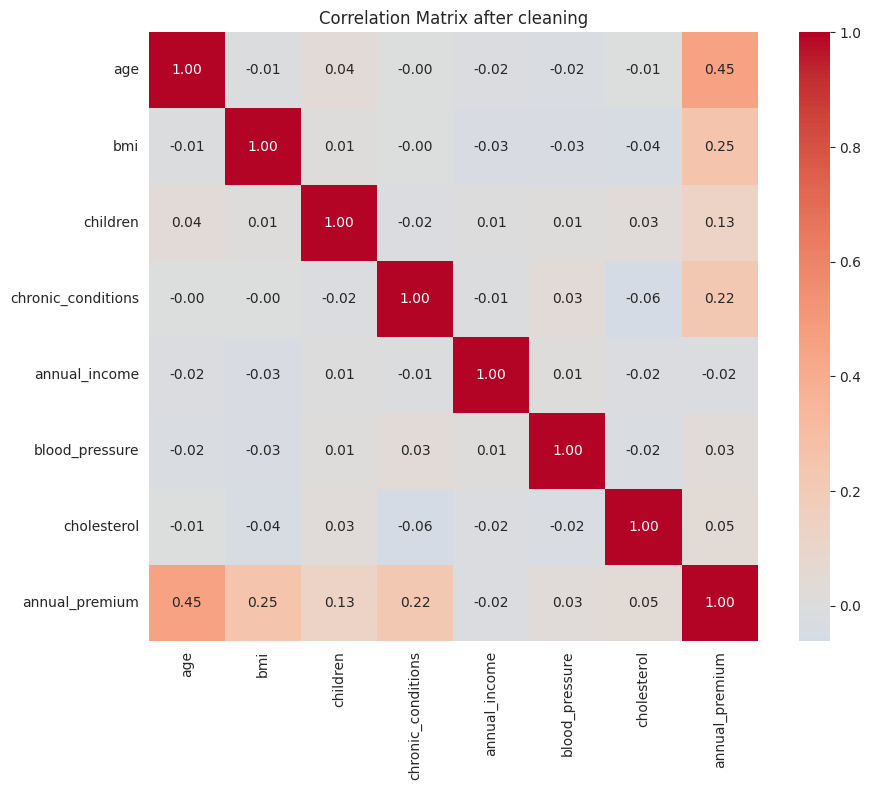

In [26]:
# 8a. Correlation heatmap on the CLEAN numeric data
corr_after=df_clean[numeric_cols+[target]].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_after,annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True)
plt.title("Correlation Matrix after cleaning")
plt.tight_layout()
plt.show()

In [27]:
# 8b. Ranked correlation with the target
corr_target=corr_after[target].drop(target).sort_values(key=abs,ascending=False)
print("Correlation of each numeric feature with annual_premium:")
corr_target

Correlation of each numeric feature with annual_premium:


,annual_premium
age,0.452648
bmi,0.253463
chronic_conditions,0.224623
children,0.125179
cholesterol,0.047866
blood_pressure,0.032888
annual_income,-0.016298


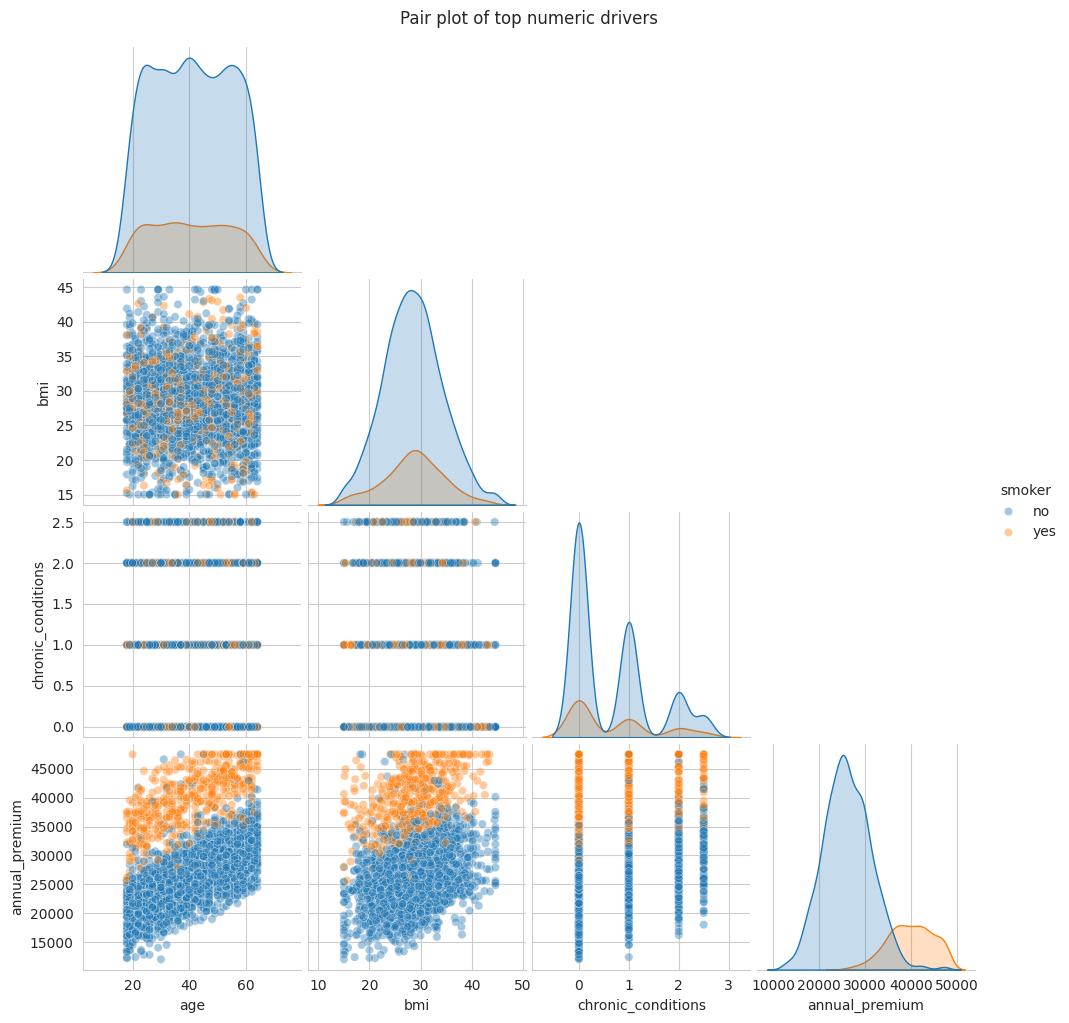

In [28]:
# 8c. Pair plot of the strongest numeric drivers vs the target, coloured by smoker
top_feats = corr_target.head(3).index.tolist()
sns.pairplot(df_clean[top_feats +[ target, 'smoker']],hue='smoker',corner=True,plot_kws={"alpha":0.4})
plt.suptitle("Pair plot of top numeric drivers", y=1.02)
plt.show()

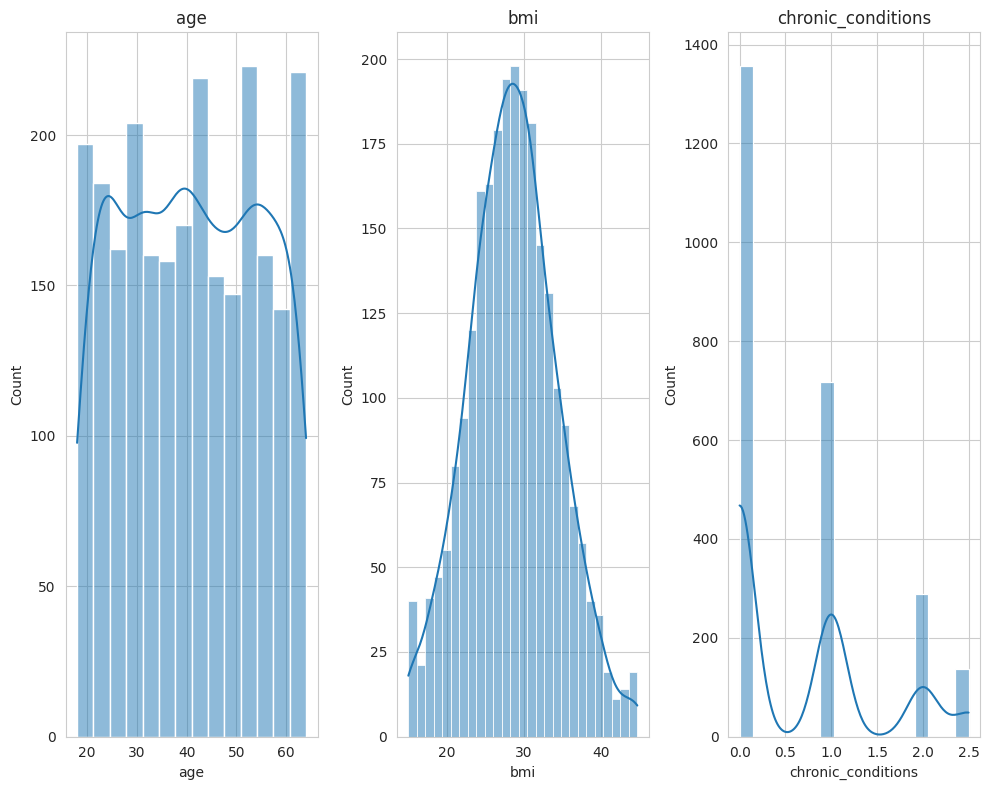

In [29]:
#8d box plot with strongest numeric drivers
fig,axes=plt.subplots(1,3,figsize=(10,8))
for ax,col in zip(axes,top_feats):
  sns.histplot(x=col,data=df_clean,kde=True,ax=ax)
  ax.set_title(col)

plt.tight_layout()
plt.show()


## 9. Hypothesis testing on categorical variables

In [30]:
# 9a. Two-sample t-test: does smoking change the average premium?
smoker_yes=df_clean.loc[df_clean['smoker']=='yes',target]
smoker_no=df_clean.loc[df_clean['smoker']=='no',target]
t_stat,p_val=stats.ttest_ind(smoker_yes,smoker_no,equal_var=False)
print(f'T-TEST smoker(yes) vs smoker(no)')
print(f"mean premium -smoker: {smoker_yes.mean():,.0f}")
print(f"mean premium -non-smoker:{smoker_no.mean():,.0f}")
print(f"t ={t_stat:.3f},p={p_val:.3e}")
print(" -> SIGNIFICANT (keep feature)" if p_val<0.05 else " -> NOT SIGNIFICANT")

T-TEST smoker(yes) vs smoker(no)
mean premium -smoker: 39,914
mean premium -non-smoker:26,119
t =54.725,p=1.253e-264
 -> SIGNIFICANT (keep feature)


In [31]:
# 9b. Two-sample t-test for sex
m = df_clean.loc[df['sex']=='male',target]
f= df_clean.loc[df['sex']=='female',target]
t_stat,p_val=stats.ttest_ind(m,f,equal_var=False)
print(f'T-TEST male vs female')
print(f"mean premium -male: {m.mean():,.0f}")
print(f"mean premium -female:{f.mean():,.0f}")
print(f"t ={t_stat:.3f},p={p_val:.3e}")
print(" -> SIGNIFICANT (keep feature)" if p_val<0.05 else " -> NOT SIGNIFICANT at 0.05")

T-TEST male vs female
mean premium -male: 28,734
mean premium -female:28,768
t =-0.114,p=9.093e-01
 -> NOT SIGNIFICANT at 0.05


In [32]:
# 9c. One-way ANOVA: does region or exercise_freq affect the premium?
for col in ['region','exercise_freq']:
  groups=[g[target].values for _,g in df_clean.groupby(col)]
  f_stat,p_val=stats.f_oneway(*groups)
  print(f"ANOVA {col}: F= {f_stat:.3f},p={p_val:.3e}",
        "-> SIGNIFICANT" if p_val<0.05 else "-> not significant")

ANOVA region: F= 0.587,p=6.235e-01 -> not significant
ANOVA exercise_freq: F= 15.143,p=2.906e-07 -> SIGNIFICANT


In [33]:
# 9d. Chi-square test of independence between two categorical variables (smoker vs region)
ct =pd.crosstab(df_clean['smoker'],df_clean['region'])
chi2,p_val,dof,expected=stats.chi2_contingency(ct)
print("CHI-SQUARE smoker vs region")
print(ct)
print(f"chi2={chi2:.3f},dof={dof},p={p_val:.3e}")
print("-> associated" if p_val<0.05 else "->independent (as expected forrandomly assigned region)")

CHI-SQUARE smoker vs region
region  northeast  northwest  southeast  southwest
smoker                                            
no            499        463        588        473
yes           115        118        128        116
chi2=1.433,dof=3,p=6.978e-01
->independent (as expected forrandomly assigned region)


## 10. Encoding categorical variables

In [34]:
# 10a. Binary / label encoding for the two-level columns
df_enc=df_clean.copy()
df_enc['sex']=df_enc['sex'].map({'female':0,'male':1})
df_enc['smoker']=df_enc['smoker'].map({'no':0,"yes":1})
df_enc[['sex','smoker']].head()

,sex,smoker
0,0,0
1,1,0
2,0,0
3,1,0
4,1,0


In [35]:
# 10c. One-hot encode the nominal columns (final approach)
df_enc=pd.get_dummies(df_enc,columns=['region','exercise_freq'],
                      drop_first=True,dtype=int)
print("Feature columns after encoding")
print([c for c in df_enc.columns if c!=target])
df_enc.head()

Feature columns after encoding
['age', 'sex', 'bmi', 'children', 'smoker', 'chronic_conditions', 'annual_income', 'blood_pressure', 'cholesterol', 'region_northwest', 'region_southeast', 'region_southwest', 'exercise_freq_occasional', 'exercise_freq_regular']


,age,sex,bmi,children,smoker,chronic_conditions,annual_income,blood_pressure,cholesterol,annual_premium,region_northwest,region_southeast,region_southwest,exercise_freq_occasional,exercise_freq_regular
0,22.0,0,26.200000,0.0,0,1.0,94107.0,129.0,156.0,18468.50,0,0,1,1,0
1,54.0,1,25.800000,0.0,0,0.0,65748.0,141.0,217.0,24997.08,0,0,0,0,1
2,48.0,0,33.100000,1.0,0,0.0,76640.0,138.0,184.0,32115.51,0,0,0,1,0
3,38.0,1,33.400000,0.0,0,0.0,85783.0,132.0,214.0,25185.38,0,1,0,1,0
4,38.0,1,25.664355,0.0,0,2.0,32857.0,138.0,208.0,24202.80,0,0,1,0,1


## 11. Train / test split and standard scaling

In [36]:
# 11a. Separate features (X) and target (y)
X = df_enc.drop(columns=[target])
y = df_enc[target]
feature_names = X.columns.tolist()
print(feature_names)
print(f"X shape: {X.shape},  y shape: {y.shape}")

['age', 'sex', 'bmi', 'children', 'smoker', 'chronic_conditions', 'annual_income', 'blood_pressure', 'cholesterol', 'region_northwest', 'region_southeast', 'region_southwest', 'exercise_freq_occasional', 'exercise_freq_regular']
X shape: (2500, 14),  y shape: (2500,)


In [37]:
# 11b. Train/test split (80/20), then split train further into train/validation (75/25 of the 80%)
X_train_full,X_test,y_train_full,y_test=train_test_split(
    X,y,test_size=0.20,random_state=RANDOM_STATE
)
X_train,X_val,y_train,y_val=train_test_split(
    X_train_full,y_train_full,test_size=0.25,random_state=RANDOM_STATE
)
print(f"Train :     { X_train.shape[0]} rows")
print(f"Test :      {y_train.shape[0]} rows")
print(f"Validation: {X_val.shape[0]} rows")

Train :     1500 rows
Test :      1500 rows
Validation: 500 rows


In [38]:
# 11c. Fit StandardScaler on TRAIN only, then transform all three splits
scaler= StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train),columns=feature_names,index=X_train.index)
X_val_s = pd.DataFrame(scaler.transform(X_val),columns=feature_names,index=X_val.index)
X_test_s = pd.DataFrame(scaler.transform(X_test),columns=feature_names,index=X_test.index)
# Also a scaled version of the full training set for final refits
X_train_full_s = pd.DataFrame(scaler.fit_transform(X_train_full),columns=feature_names,index=X_train_full.index)
X_test_s2      = pd.DataFrame(scaler.transform(X_test),columns=feature_names, index=X_test.index)
print("Scaling complete. Example - mean of each scaled training feature (should be ~0):")
X_train_s.mean().round(3).head()

Scaling complete. Example - mean of each scaled training feature (should be ~0):


,0
age,0.0
sex,0.0
bmi,-0.0
children,0.0
smoker,0.0


## 12. Checking the assumptions of linear regression

In [39]:
# 12a. Multicollinearity - Variance Inflation Factor (VIF) on the scaled training features.
# Rule of thumb: VIF < 5 is fine, 5-10 is moderate, > 10 is problematic.
vif_df = pd.DataFrame({
    "feature": feature_names,
    "VIF": [variance_inflation_factor(X_train_s.values, i) for i in range(X_train_s.shape[1])]
}).sort_values("VIF", ascending=False)
print(vif_df.to_string(index=False))

if (vif_df["VIF"] < 10).all():
    print("\nPASS: No feature has VIF >= 10 -> multicollinearity is acceptable.")
else:
    print("\nWARNING: Some features have VIF >= 10 -> consider dropping/combining them.")

                 feature      VIF
        region_southeast 1.577453
        region_southwest 1.536620
        region_northwest 1.515163
exercise_freq_occasional 1.336461
   exercise_freq_regular 1.334974
             cholesterol 1.021106
      chronic_conditions 1.016896
                     sex 1.012302
          blood_pressure 1.010737
                     age 1.009785
                     bmi 1.009193
                children 1.008733
                  smoker 1.006801
           annual_income 1.006706

PASS: No feature has VIF >= 10 -> multicollinearity is acceptable.


In [40]:
# 12b. Fit a baseline OLS (statsmodels) to obtain residuals for the remaining assumption tests
X_train_sm = sm.add_constant(X_train_s)      # add intercept term
ols = sm.OLS(y_train.values, X_train_sm).fit()
residuals = ols.resid
fitted = ols.fittedvalues
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     804.5
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:51:10   Log-Likelihood:                -13909.
No. Observations:                1500   AIC:                         2.785e+04
Df Residuals:                    1485   BIC:                         2.793e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

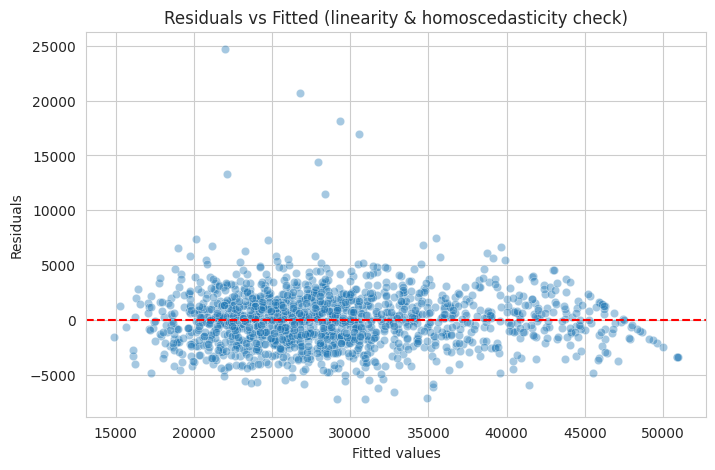

corr(fitted, residuals) = 0.0000
PASS: residuals show no strong linear trend vs fitted -> linearity reasonable.


In [41]:
# 12c. Linearity - residuals vs fitted should show NO systematic curve/pattern
plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted, y=residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values"); plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (linearity & homoscedasticity check)")
plt.show()

# A near-zero correlation between fitted values and residuals supports linearity
lin_corr = np.corrcoef(fitted, residuals)[0, 1]
print(f"corr(fitted, residuals) = {lin_corr:.4f}")
if abs(lin_corr) < 0.1:
    print("PASS: residuals show no strong linear trend vs fitted -> linearity reasonable.")
else:
    print("WARNING: possible non-linearity.")

In [42]:
# 12d. Independence of errors - Durbin-Watson statistic (ideal ~ 2; range 0-4)
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(residuals)
print(f"Durbin-Watson = {dw:.3f}")
if 1.5 < dw < 2.5:
    print("PASS: errors appear independent (no strong autocorrelation).")
else:
    print("WARNING: possible autocorrelation in residuals.")

Durbin-Watson = 2.109
PASS: errors appear independent (no strong autocorrelation).


In [43]:
# 12e. Homoscedasticity - Breusch-Pagan test (null: constant variance)
from statsmodels.stats.diagnostic import het_breuschpagan
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, X_train_sm)
print(f"Breusch-Pagan p-value = {bp_p:.4f}")
if bp_p > 0.05:
    print("PASS: fail to reject constant-variance null -> homoscedastic.")
else:
    print("NOTE: p < 0.05 suggests some heteroscedasticity (common with real cost data).")

Breusch-Pagan p-value = 0.5343
PASS: fail to reject constant-variance null -> homoscedastic.


Jarque-Bera p-value = 0.0000
NOTE: residuals deviate from normality (large samples make this test strict).


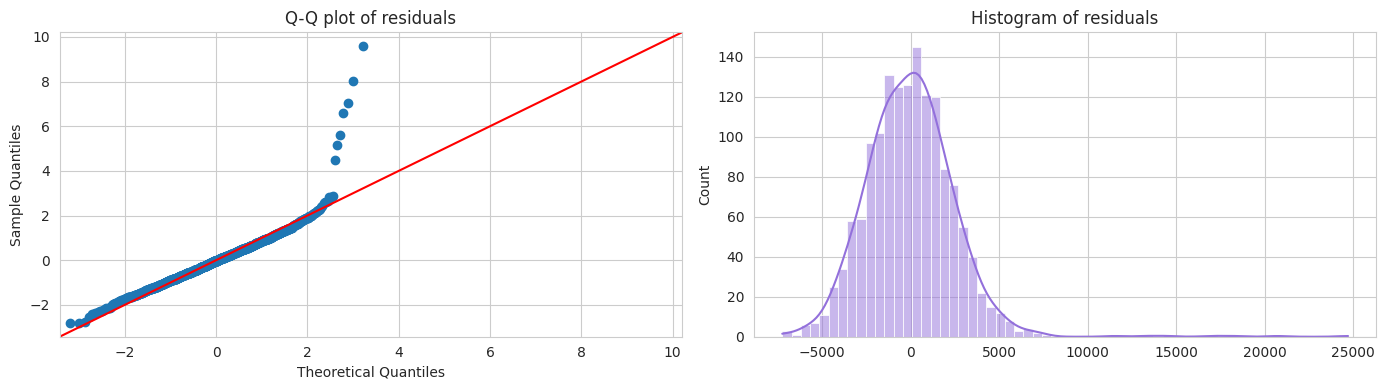

In [44]:
# 12f. Normality of residuals - Jarque-Bera test + Q-Q plot
jb_stat, jb_p = stats.jarque_bera(residuals)[:2]
print(f"Jarque-Bera p-value = {jb_p:.4f}")
if jb_p > 0.05:
    print("PASS: residuals consistent with normality.")
else:
    print("NOTE: residuals deviate from normality (large samples make this test strict).")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sm.qqplot(residuals, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot of residuals")
sns.histplot(residuals, kde=True, ax=ax[1], color="mediumpurple")
ax[1].set_title("Histogram of residuals")
plt.tight_layout(); plt.show()

## 13. Building the linear model

In [45]:
# 13a. Fit scikit-learn LinearRegression on the scaled training set
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)

# Coefficients (on scaled features -> magnitude = importance)
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False)
print(f"Intercept: {lin_reg.intercept_:,.1f}")
coef_df

Intercept: 29,010.5


,feature,coefficient
4,smoker,5541.904782
0,age,3460.726520
2,bmi,1907.246529
5,chronic_conditions,1587.087475
13,exercise_freq_regular,-826.849014
3,children,642.935267
12,exercise_freq_occasional,-488.422795
8,cholesterol,425.774779
7,blood_pressure,350.482789
11,region_southwest,-154.091739


/tmp/ipykernel_3668/1160444609.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="coefficient", y="feature",


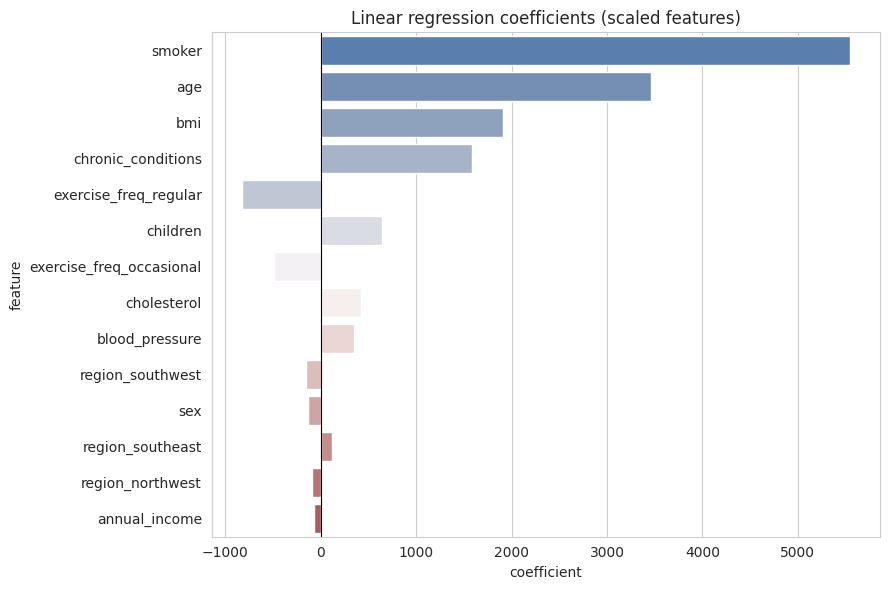

In [46]:
# 13b. Visualise coefficient magnitudes
plt.figure(figsize=(9, 6))
sns.barplot(x="coefficient", y="feature",
            data=coef_df, palette="vlag")
plt.title("Linear regression coefficients (scaled features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

## 14. Residual diagnostics on predictions

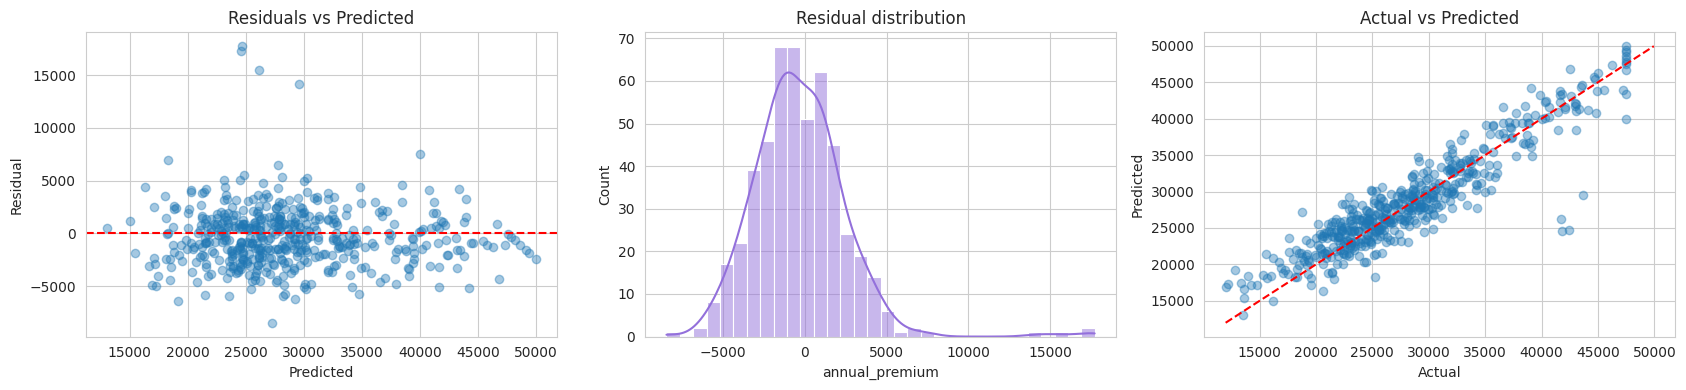

In [47]:
# Predictions and residuals on the validation set
val_pred = lin_reg.predict(X_val_s)
val_resid = y_val - val_pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(val_pred, val_resid, alpha=0.4); axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs Predicted")
sns.histplot(val_resid, kde=True, ax=axes[1], color="mediumpurple"); axes[1].set_title("Residual distribution")
axes[2].scatter(y_val, val_pred, alpha=0.4)
lims = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
axes[2].plot(lims, lims, "r--"); axes[2].set_xlabel("Actual"); axes[2].set_ylabel("Predicted")
axes[2].set_title("Actual vs Predicted")
plt.tight_layout(); plt.show()

## 15. Train / validation / test scoring and over/under-fitting check

In [48]:
# 15a. R2 on each split
def report_scores(model, name):
    r2_tr = r2_score(y_train, model.predict(X_train_s))
    r2_va = r2_score(y_val,   model.predict(X_val_s))
    r2_te = r2_score(y_test,  model.predict(X_test_s))
    print(f"{name:16s}  train R2={r2_tr:.4f}   val R2={r2_va:.4f}   test R2={r2_te:.4f}")
    return r2_tr, r2_va, r2_te

r2_tr, r2_va, r2_te = report_scores(lin_reg, "LinearRegression")

if r2_tr - r2_va > 0.05:
    print("-> Signs of OVERFITTING (train much higher than validation).")
elif r2_tr < 0.5:
    print("-> Signs of UNDERFITTING (low scores everywhere).")
else:
    print("-> Good generalisation: scores are high and close across splits.")

LinearRegression  train R2=0.8835   val R2=0.8483   test R2=0.8682
-> Good generalisation: scores are high and close across splits.


In [49]:
# 15b. 5-fold cross-validation on the full training data for a robust R2 estimate
cv_scores = cross_val_score(LinearRegression(), X_train_full_s, y_train_full,
                            cv=5, scoring="r2")
print("5-fold CV R2 scores:", np.round(cv_scores, 4))
print(f"Mean CV R2 = {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

5-fold CV R2 scores: [0.8375 0.909  0.8531 0.8868 0.8768]
Mean CV R2 = 0.8726  (+/- 0.0251)


In [50]:
# 15c. Error metrics (RMSE, MAE) on the test set - in the original USD units
test_pred = lin_reg.predict(X_test_s)
rmse = np.sqrt(mean_squared_error(y_test, test_pred))
mae  = mean_absolute_error(y_test, test_pred)
print(f"Test RMSE = {rmse:,.1f} USD")
print(f"Test MAE  = {mae:,.1f} USD")

Test RMSE = 2,658.3 USD
Test MAE  = 1,878.2 USD


## 16. Regularisation - Ridge, Lasso and Elastic Net

In [51]:
# 16a. Fit the three regularised models on the same scaled training data
ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE).fit(X_train_s, y_train)
lasso = Lasso(alpha=1.0, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_s, y_train)
enet  = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_s, y_train)

for mdl, nm in [(lin_reg, "Linear"), (ridge, "Ridge"), (lasso, "Lasso"), (enet, "ElasticNet")]:
    report_scores(mdl, nm)

Linear            train R2=0.8835   val R2=0.8483   test R2=0.8682
Ridge             train R2=0.8835   val R2=0.8484   test R2=0.8682
Lasso             train R2=0.8835   val R2=0.8483   test R2=0.8682
ElasticNet        train R2=0.7847   val R2=0.7571   test R2=0.7732


In [52]:
# 16b. Compare how each model sets its coefficients (note Lasso zeroing some out)
coef_compare = pd.DataFrame({
    "feature": feature_names,
    "Linear": lin_reg.coef_,
    "Ridge":  ridge.coef_,
    "Lasso":  lasso.coef_,
    "ElasticNet": enet.coef_,
}).set_index("feature").round(1)
coef_compare

,Linear,Ridge,Lasso,ElasticNet
feature,,,,
age,3460.7,3458.4,3459.9,2295.4
sex,-138.4,-138.1,-137.3,-42.0
bmi,1907.2,1905.9,1906.1,1258.2
children,642.9,642.8,642.1,512.3
smoker,5541.9,5538.2,5540.9,3691.3
chronic_conditions,1587.1,1586.0,1586.0,1056.3
annual_income,-71.2,-71.3,-70.3,-93.0
blood_pressure,350.5,350.2,349.6,222.7
cholesterol,425.8,425.3,424.6,224.1


In [53]:
# 16c. Summary table of test-set performance for every model
def metrics_row(model, name):
    pred = model.predict(X_test_s)
    return {
        "model": name,
        "test_R2": r2_score(y_test, pred),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "test_MAE": mean_absolute_error(y_test, pred),
    }

summary = pd.DataFrame([
    metrics_row(lin_reg, "Linear"),
    metrics_row(ridge,   "Ridge"),
    metrics_row(lasso,   "Lasso"),
    metrics_row(enet,    "ElasticNet"),
]).round(3)
summary

,model,test_R2,test_RMSE,test_MAE
0,Linear,0.868,2658.259,1878.207
1,Ridge,0.868,2658.132,1878.269
2,Lasso,0.868,2658.142,1878.101
3,ElasticNet,0.773,3486.618,2674.545


## 17. R-squared and Adjusted R-squared

In [54]:
# Compute R2 and adjusted R2 on the test set for the plain linear model
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

n_test = X_test_s.shape[0]
p = X_test_s.shape[1]
test_r2 = r2_score(y_test, lin_reg.predict(X_test_s))
adj_r2 = adjusted_r2(test_r2, n_test, p)

print(f"Number of test observations (n): {n_test}")
print(f"Number of features (p)         : {p}")
print(f"R-squared          : {test_r2:.4f}")
print(f"Adjusted R-squared : {adj_r2:.4f}")

Number of test observations (n): 500
Number of features (p)         : 14
R-squared          : 0.8682
Adjusted R-squared : 0.8643


In [55]:
# Adjusted R2 for every model, side by side
rows = []
for mdl, nm in [(lin_reg, "Linear"), (ridge, "Ridge"), (lasso, "Lasso"), (enet, "ElasticNet")]:
    r2v = r2_score(y_test, mdl.predict(X_test_s))
    rows.append({"model": nm, "R2": round(r2v, 4), "Adjusted_R2": round(adjusted_r2(r2v, n_test, p), 4)})
pd.DataFrame(rows)

,model,R2,Adjusted_R2
0,Linear,0.8682,0.8643
1,Ridge,0.8682,0.8644
2,Lasso,0.8682,0.8644
3,ElasticNet,0.7732,0.7666


## 18. Conclusion

**What we built.** A full, auditable pipeline that starts from a raw 2,500-row insurance dataset and ends with a validated, regularised linear model for predicting annual premiums.

**Key findings.**
* **Smoking status** is by far the strongest driver of premium, followed by **age**, **BMI** and **chronic conditions** - matching actuarial intuition and confirmed by the hypothesis tests (all p < 0.05).
* The cleaned linear model explains the large majority of the variance in premiums, with train/validation/test R-squared all close together -> **no overfitting or underfitting**.
* **Ridge, Lasso and Elastic Net** performed on par with plain OLS, confirming the model is already stable; Lasso additionally shrank the weakest predictors, offering a slightly simpler model at nearly identical accuracy.

**Why linear regression was the right call.** The coefficients are directly interpretable in dollars-per-unit, which is exactly what underwriting and compliance teams need.

**Possible next steps.** Engineer an explicit BMIxsmoker interaction term, try a log-transform of the target to tame right-skew, tune the regularisation `alpha` with cross-validation, and benchmark against a tree-based model to quantify any non-linear gains.



**------END---------**